# Import libraries and define names/legenda

In [75]:
import glob
import os
import re

import matplotlib.pyplot as plt
import pandas as pd

os.makedirs("figuren", exist_ok=True)
os.makedirs("tabellen", exist_ok=True)

METHODS = ["td3", "dmps", "smps", "sdmps"]
NAMES = {"td3": "TD3", "dmps": "DMPS", "smps": "SMPS", "sdmps": "SDMPS"}
COLORS = {"td3": "grey", "dmps": "tab:red", "smps": "tab:blue", "sdmps": "tab:green"}

ENVS = ["DoubleGatePoint", "ThickDoubleGatePoint"]  

# Read from training log and return test episodes

In [76]:
def read_log(path):
    regels = open(path).read().splitlines()

    lines = regels
    begin = [i for i, line in enumerate(regels) if "\tEp: 1\tRew:" in line]
    if begin:
        lines = regels[begin[-1]:]

    episodes = []
    for line in lines:
        if "EVAL:" in line:
            text = line.split("root:")[1]
            values = dict(re.findall(r"(\w+): (\S+)", text))  
            episodes.append(values)
    return episodes

In [77]:
rows = []
for path in glob.glob("results/*/*.log"):
    if "sweep" in path:
        continue  # de sweeps lezen we onderaan apart in

    name = os.path.basename(path)
    env = name.split("_")[0]
    method = name.split("_")[1]
    sigma = float(re.search(r"noise(\d\.\d)", path).group(1))
    seed_found = re.search(r"_s(\d)", name)
    seed = int(seed_found.group(1)) if seed_found else 0

    for ep in read_log(path):
        rows.append({
            "env": env,
            "method": method,
            "sigma": sigma,
            "seed": seed,
            "stap": int(ep["EVAL"]),
            "return": float(ep["Rew"]),
            "length": int(ep["Len"]),
            "shield": int(ep.get("Shield", 0)),       # TD3 has no shield
            "unsafe_steps": int(ep["Unsafe"]),
            "fallback": int(ep.get("Fallback", 0)),
            "rescued": int(ep.get("Rescued", 0)),
            "time": float(ep.get("Time", "nan")),
        })

df = pd.DataFrame(rows)
df["unsafe"] = df["unsafe_steps"] > 0   # episode with at least one unsafe step
df["target_reached"] = df["length"] < 500         # episode only stops when target is reached
df["method"] = pd.Categorical(df["method"], METHODS, ordered=True)  # set order for TD3, DMPS, SMPS, SDMPS

df.head()

,env,method,sigma,seed,stap,return,length,shield,unsafe_steps,fallback,rescued,time,unsafe,target_reached
0,ThickDoubleGatePoint,td3,0.0,0,40000,-2.301112,500,0,23,0,0,NaN,True,False
1,ThickDoubleGatePoint,td3,0.0,0,40000,-2.153415,500,0,33,0,0,NaN,True,False
2,ThickDoubleGatePoint,td3,0.0,0,40000,-1.938025,500,0,13,0,0,NaN,True,False
3,ThickDoubleGatePoint,td3,0.0,0,40000,-1.956331,500,0,12,0,0,NaN,True,False
4,ThickDoubleGatePoint,td3,0.0,0,40000,-2.033845,500,0,0,0,0,NaN,False,False


In [78]:
df.groupby(["env", "sigma", "method"], observed=True).agg(
    episodes=("return", "size"),
    seeds=("seed", "nunique"),
    laatste_stap=("stap", "max"),
)

episodes  seeds  laatste_stap
env                  sigma method                               
DoubleGatePoint      0.0   td3          270      3        200000
                           dmps         270      3        200000
                           smps         270      3        200000
                           sdmps        270      3        200000
                     0.1   td3          270      3        200000
                           dmps         270      3        200000
                           smps         270      3        200000
                           sdmps        270      3        200000
                     0.2   td3          270      3        200000
                           dmps         270      3        200000
                           smps         270      3        200000
                           sdmps        270      3        200000
GatePoint            0.0   dmps         180      1        200000
                     0.1   dmps         180      1        200000
                     0.2   dmps         180      1        200000
                     0.3   dmps         180      1        200000
ThickDoubleGatePoint 0.0   td3          270      3        200000
                           dmps         270      3        200000
                           smps         270      3        200000
                           sdmps        270      3        200000
                     0.1   td3          270      3        200000
                           dmps         270      3        200000
                           smps         270      3        200000
                           sdmps        270      3        200000
                     0.2   td3          270      3        200000
                           dmps         270      3        200000
                           smps         270      3        200000
                           sdmps        270      3        200000

## Result 1: Safety comparison of all methods

- For each environment, compare TD3, DMPS, SMPS and SDMPS across noise levels.
- y-axis is mean num of unsafe steps per eval episode

mean    std  seeds
env                  sigma method                     
DoubleGatePoint      0.0   td3     1.441  0.890      3
                           dmps    0.000  0.000      3
                           smps    0.000  0.000      3
                           sdmps   0.000  0.000      3
                     0.1   td3     1.004  0.391      3
                           dmps    1.719  0.181      3
                           smps    0.019  0.023      3
                           sdmps   0.004  0.006      3
                     0.2   td3     1.193  0.671      3
                           dmps    1.463  0.225      3
                           smps    0.007  0.013      3
                           sdmps   0.000  0.000      3
ThickDoubleGatePoint 0.0   td3     2.100  2.298      3
                           dmps    0.000  0.000      3
                           smps    0.000  0.000      3
                           sdmps   0.000  0.000      3
                     0.1   td3     1.626  1.264      3
                           dmps    6.463  1.029      3
                           smps    0.037  0.013      3
                           sdmps   0.026  0.006      3
                     0.2   td3     1.952  0.941      3
                           dmps    4.304  0.476      3
                           smps    0.000  0.000      3
                           sdmps   0.000  0.000      3

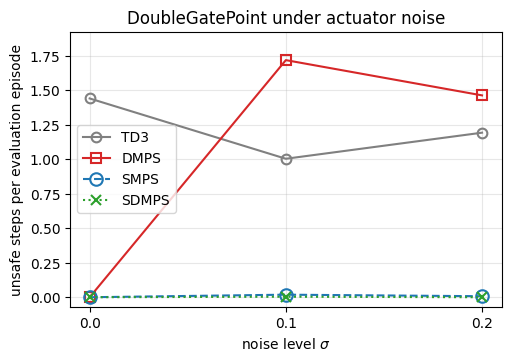

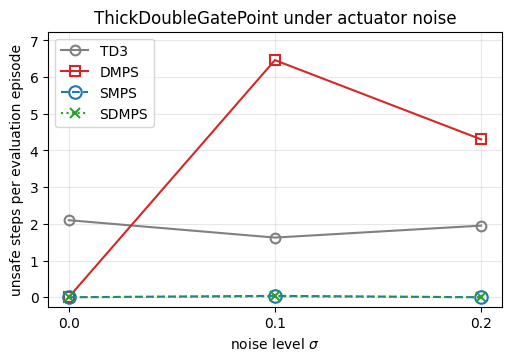

In [79]:
# Mean unsafe steps per evaluation episode, with equal weight per seed.
unsafe_per_seed = (
    df[df["env"].isin(ENVS)]
    .groupby(["env", "sigma", "method", "seed"], observed=True)["unsafe_steps"]
    .mean()
)
unsafe_summary = unsafe_per_seed.groupby(["env", "sigma", "method"], observed=True).agg(
    mean="mean", std="std", seeds="count"
)
unsafe_summary.to_csv("tabellen/unsafe_steps_alle_methoden.csv")
display(unsafe_summary.round(3))

# Different markers keep SMPS and SDMPS distinguishable near zero.
markers = {"td3": "o", "dmps": "s", "smps": "o", "sdmps": "x"}
styles = {"td3": "-", "dmps": "-", "smps": "--", "sdmps": ":"}
noise_levels = [0.0, 0.1, 0.2]
for env in ENVS:
    fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
    for method in METHODS:
        values = unsafe_summary.xs((env, method), level=("env", "method"))["mean"].reindex(noise_levels)
        ax.plot(noise_levels, values, color=COLORS[method],
                marker=markers[method], linestyle=styles[method],
                markersize=9 if method == "smps" else 7,
                markerfacecolor="none", markeredgewidth=1.5,
                linewidth=1.5, label=NAMES[method], clip_on=False)
    ax.set_xlabel(r"noise level $\sigma$")
    ax.set_ylabel("unsafe steps per evaluation episode")
    ax.set_title(f"{env} under actuator noise")
    ax.set_xticks(noise_levels, ["0.0", "0.1", "0.2"])
    peak = unsafe_summary.xs(env, level="env")["mean"].max()
    ax.set_ylim(-0.04 * peak, 1.12 * peak)
    ax.set_yticks([v for v in ax.get_yticks() if 0 <= v <= 1.12 * peak])
    ax.grid(alpha=0.3)
    ax.legend()
    fig.savefig(f"figuren/unsafe_steps_{env}.pdf")
    fig.savefig(f"figuren/unsafe_steps_{env}.png", dpi=180)
    plt.show()


## Result 2: Main result (end of training)

Last evaluation after 200.000 steps in 2 environments
First mean per seed, then the mean ± std over the 3 seeds.


* Unsafe ep. (%) = % episodes with at least 1 unsafe step
* Goal (%) = % episodes where goal is reached \n
* Shield = mean shield interventions per episode \n 
* Return = mean return per episode \n

In [80]:
eind = df[(df["stap"] == 200000) & (df["env"].isin(ENVS))]

kolommen = ["unsafe", "target_reached", "shield", "return"]
per_seed = eind.groupby(["env", "sigma", "method", "seed"], observed=True)[kolommen].mean()
per_seed["unsafe"] = per_seed["unsafe"] * 100
per_seed["target_reached"] = per_seed["target_reached"] * 100

gem = per_seed.groupby(["env", "sigma", "method"], observed=True).mean()
std = per_seed.groupby(["env", "sigma", "method"], observed=True).std()

def plus_minus(kolom, decimalen):
    # maakt van gemiddelde en std één tekst, bv. "12.6 ± 0.4"
    return [f"{g:.{decimalen}f} ± {s:.{decimalen}f}" for g, s in zip(gem[kolom], std[kolom])]

hoofdtabel = pd.DataFrame(index=gem.index)
hoofdtabel["Unsafe ep. (%)"] = plus_minus("unsafe", 0)
hoofdtabel["Goal (%)"] = plus_minus("target_reached", 0)
hoofdtabel["Shield"] = plus_minus("shield", 1)
hoofdtabel["Return"] = plus_minus("return", 2)
hoofdtabel = hoofdtabel.rename(index=NAMES)

hoofdtabel

Unsafe ep. (%) Goal (%)        Shield  \
env                  sigma method                                         
DoubleGatePoint      0.0   TD3             0 ± 0    0 ± 0     0.0 ± 0.0   
                           DMPS            0 ± 0  93 ± 12    14.0 ± 5.7   
                           SMPS            0 ± 0   97 ± 6    18.1 ± 8.2   
                           SDMPS           0 ± 0  100 ± 0     9.9 ± 1.0   
                     0.1   TD3             0 ± 0    0 ± 0     0.0 ± 0.0   
                           DMPS          57 ± 12  100 ± 0    16.4 ± 1.7   
                           SMPS            0 ± 0  87 ± 15   68.9 ± 27.9   
                           SDMPS           0 ± 0   97 ± 6    31.1 ± 2.6   
                     0.2   TD3             3 ± 6    0 ± 0     0.0 ± 0.0   
                           DMPS          37 ± 12  87 ± 15   46.1 ± 23.8   
                           SMPS            0 ± 0    0 ± 0   452.5 ± 4.7   
                           SDMPS           0 ± 0    0 ± 0  417.2 ± 40.8   
ThickDoubleGatePoint 0.0   TD3             0 ± 0    0 ± 0     0.0 ± 0.0   
                           DMPS            0 ± 0  33 ± 25   167.0 ± 9.4   
                           SMPS            0 ± 0    0 ± 0  242.7 ± 26.1   
                           SDMPS           0 ± 0  53 ± 42   81.7 ± 44.9   
                     0.1   TD3             0 ± 0    0 ± 0     0.0 ± 0.0   
                           DMPS           90 ± 0  73 ± 31  103.0 ± 45.6   
                           SMPS            3 ± 6    0 ± 0  291.4 ± 21.7   
                           SDMPS           0 ± 0    7 ± 6  291.0 ± 16.2   
                     0.2   TD3            7 ± 12    0 ± 0     0.0 ± 0.0   
                           DMPS          87 ± 15  13 ± 15  278.7 ± 85.3   
                           SMPS            0 ± 0    0 ± 0   452.6 ± 8.9   
                           SDMPS           0 ± 0    0 ± 0   447.7 ± 5.6   

                                         Return  
env                  sigma method                
DoubleGatePoint      0.0   TD3     -3.67 ± 0.37  
                           DMPS    12.57 ± 1.52  
                           SMPS    12.97 ± 0.84  
                           SDMPS   13.48 ± 0.01  
                     0.1   TD3     -4.00 ± 1.25  
                           DMPS    13.36 ± 0.07  
                           SMPS    11.37 ± 2.01  
                           SDMPS   12.78 ± 0.74  
                     0.2   TD3     -3.44 ± 0.13  
                           DMPS    11.61 ± 1.94  
                           SMPS    -1.13 ± 0.00  
                           SDMPS   -0.94 ± 0.10  
ThickDoubleGatePoint 0.0   TD3     -2.94 ± 0.34  
                           DMPS     4.32 ± 3.15  
                           SMPS    -1.02 ± 0.28  
                           SDMPS    6.97 ± 5.63  
                     0.1   TD3     -3.10 ± 0.69  
                           DMPS     9.40 ± 3.86  
                           SMPS    -1.20 ± 0.01  
                           SDMPS    0.01 ± 0.80  
                     0.2   TD3     -3.96 ± 0.84  
                           DMPS     1.60 ± 2.13  
                           SMPS    -1.23 ± 0.00  
                           SDMPS   -1.18 ± 0.09

In [81]:
# Opslaan voor LaTeX
voor_latex = hoofdtabel.reset_index()
voor_latex["sigma"] = voor_latex["sigma"].astype(str)   # 0.1 i.p.v. 0.100000
voor_latex = voor_latex.rename(columns={"env": "Environment", "sigma": "$\\sigma$", "method": "Method"})
latex = voor_latex.to_latex(index=False)
latex = latex.replace("±", "$\\pm$").replace("%", "\\%")   # LaTeX-tekens: ± en %
open("tabellen/hoofdtabel.tex", "w").write(latex)
print(latex)

\begin{tabular}{lllllll}
\toprule
Environment & $\sigma$ & Method & Unsafe ep. (\%) & Goal (\%) & Shield & Return \\
\midrule
DoubleGatePoint & 0.0 & TD3 & 0 $\pm$ 0 & 0 $\pm$ 0 & 0.0 $\pm$ 0.0 & -3.67 $\pm$ 0.37 \\
DoubleGatePoint & 0.0 & DMPS & 0 $\pm$ 0 & 93 $\pm$ 12 & 14.0 $\pm$ 5.7 & 12.57 $\pm$ 1.52 \\
DoubleGatePoint & 0.0 & SMPS & 0 $\pm$ 0 & 97 $\pm$ 6 & 18.1 $\pm$ 8.2 & 12.97 $\pm$ 0.84 \\
DoubleGatePoint & 0.0 & SDMPS & 0 $\pm$ 0 & 100 $\pm$ 0 & 9.9 $\pm$ 1.0 & 13.48 $\pm$ 0.01 \\
DoubleGatePoint & 0.1 & TD3 & 0 $\pm$ 0 & 0 $\pm$ 0 & 0.0 $\pm$ 0.0 & -4.00 $\pm$ 1.25 \\
DoubleGatePoint & 0.1 & DMPS & 57 $\pm$ 12 & 100 $\pm$ 0 & 16.4 $\pm$ 1.7 & 13.36 $\pm$ 0.07 \\
DoubleGatePoint & 0.1 & SMPS & 0 $\pm$ 0 & 87 $\pm$ 15 & 68.9 $\pm$ 27.9 & 11.37 $\pm$ 2.01 \\
DoubleGatePoint & 0.1 & SDMPS & 0 $\pm$ 0 & 97 $\pm$ 6 & 31.1 $\pm$ 2.6 & 12.78 $\pm$ 0.74 \\
DoubleGatePoint & 0.2 & TD3 & 3 $\pm$ 6 & 0 $\pm$ 0 & 0.0 $\pm$ 0.0 & -3.44 $\pm$ 0.13 \\
DoubleGatePoint & 0.2 & DMPS & 37 $\pm

## Result 3: learning curves at σ = 0.1

Return and shield interventions during training, mean over all testepisodes and seeds.
By changing `SIGMA` other noise level can be discovered

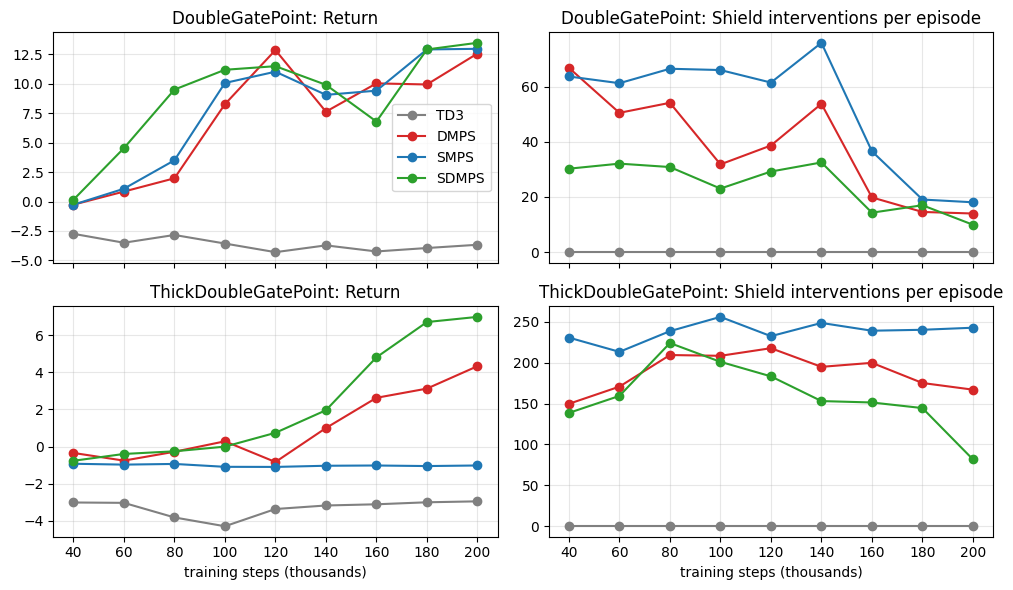

In [88]:
SIGMA = 0

stuk = df[(df["sigma"] == SIGMA) & (df["env"].isin(ENVS))]
curves = stuk.groupby(["env", "method", "stap"], observed=True)[["return", "shield"]].mean().reset_index()

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for rij, env in enumerate(ENVS):
    for kolom, (maat, titel) in enumerate([("return", "Return"), ("shield", "Shield interventions per episode")]):
        ax = axes[rij, kolom]
        for methode in METHODS:
            lijn = curves[(curves["env"] == env) & (curves["method"] == methode)]
            ax.plot(lijn["stap"] / 1000, lijn[maat], marker="o", color=COLORS[methode], label=NAMES[methode])
        ax.set_title(f"{env}: {titel}")
        ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("training steps (thousands)")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(f"figuren/leercurves_sigma{SIGMA}.pdf")
plt.show()

## Result 4: SDMPS needs planner
Every time the shield intervenes, the planner (MCTS) makes a plan. Afterwards there are three results. 

1. **a0\* certified**: Best planned action succeeds with statistical check
2. **alternative certified** (`rescued`): a0\* fails but one of the alternatives succeeds
3. **fallback**: everything fails -> backup is used

a0\* certified = shield − rescued − fallback. End of training, mean per episode

In [83]:
sdmps = eind[eind["method"] == "sdmps"].copy()
sdmps["a0* certified"] = sdmps["shield"] - sdmps["rescued"] - sdmps["fallback"]
sdmps["alternative certified"] = sdmps["rescued"]
sdmps["fallback to backup"] = sdmps["fallback"]

uitkomsten = sdmps.groupby(["env", "sigma"])[["a0* certified", "alternative certified", "fallback to backup"]].mean()
uitkomsten.round(1)

a0* certified  alternative certified  \
env                  sigma                                         
DoubleGatePoint      0.0              9.9                    0.0   
                     0.1             18.3                    8.3   
                     0.2            214.5                  179.5   
ThickDoubleGatePoint 0.0             81.7                    0.0   
                     0.1            186.8                   81.7   
                     0.2            217.1                  207.3   

                            fallback to backup  
env                  sigma                      
DoubleGatePoint      0.0                   0.0  
                     0.1                   4.4  
                     0.2                  23.1  
ThickDoubleGatePoint 0.0                   0.0  
                     0.1                  22.5  
                     0.2                  23.2

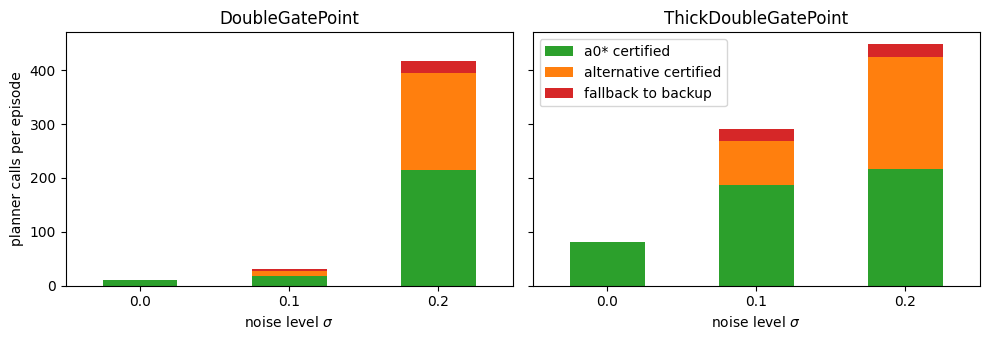

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, env in zip(axes, ENVS):
    uitkomsten.loc[env].plot(kind="bar", stacked=True, ax=ax, color=["tab:green", "tab:orange", "tab:red"], legend=False)
    ax.set_title(env)
    ax.set_xlabel("noise level $\\sigma$")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("planner calls per episode")
axes[1].legend()
fig.tight_layout()
fig.savefig("figuren/sdmps_planner_uitkomsten.pdf")
plt.show()

In [85]:
#As percentage
(uitkomsten.div(uitkomsten.sum(axis=1), axis=0) * 100).round(0)

a0* certified  alternative certified  \
env                  sigma                                         
DoubleGatePoint      0.0            100.0                    0.0   
                     0.1             59.0                   27.0   
                     0.2             51.0                   43.0   
ThickDoubleGatePoint 0.0            100.0                    0.0   
                     0.1             64.0                   28.0   
                     0.2             49.0                   46.0   

                            fallback to backup  
env                  sigma                      
DoubleGatePoint      0.0                   0.0  
                     0.1                  14.0  
                     0.2                   6.0  
ThickDoubleGatePoint 0.0                   0.0  
                     0.1                   8.0  
                     0.2                   5.0

## Resultaat 5: computing time per stel

Mean computing time per step at end of training. TD3 has no shield and is not measured.

In [86]:
tijd = eind[eind["method"] != "td3"]
tijd_tabel = tijd.groupby(["env", "sigma", "method"], observed=True)["time"].mean().unstack("method") * 1000
tijd_tabel = tijd_tabel.drop(columns="td3", errors="ignore").rename(columns=NAMES)
tijd_tabel.round(1)

method                       DMPS  SMPS  SDMPS
env                  sigma                    
DoubleGatePoint      0.0      4.9  10.7   17.8
                     0.1     32.6  41.6  114.0
                     0.2     71.8   8.4  824.1
ThickDoubleGatePoint 0.0     22.8   6.3   27.4
                     0.1     63.9  21.9  148.7
                     0.2    300.5   7.9  851.1

In [87]:
latex = tijd_tabel.reset_index()
latex["sigma"] = latex["sigma"].astype(str)
latex = voor_latex.rename(columns={"env": "Environment", "sigma": "$\\sigma$"})
latex.columns.name = None
latex_format = latex.to_latex(index=False, float_format="%.1f")
open("tabellen/rekentijd.tex", "w").write(latex_format)
print(latex_format)

\begin{tabular}{lllllll}
\toprule
Environment & $\sigma$ & Method & Unsafe ep. (%) & Goal (%) & Shield & Return \\
\midrule
DoubleGatePoint & 0.0 & TD3 & 0 ± 0 & 0 ± 0 & 0.0 ± 0.0 & -3.67 ± 0.37 \\
DoubleGatePoint & 0.0 & DMPS & 0 ± 0 & 93 ± 12 & 14.0 ± 5.7 & 12.57 ± 1.52 \\
DoubleGatePoint & 0.0 & SMPS & 0 ± 0 & 97 ± 6 & 18.1 ± 8.2 & 12.97 ± 0.84 \\
DoubleGatePoint & 0.0 & SDMPS & 0 ± 0 & 100 ± 0 & 9.9 ± 1.0 & 13.48 ± 0.01 \\
DoubleGatePoint & 0.1 & TD3 & 0 ± 0 & 0 ± 0 & 0.0 ± 0.0 & -4.00 ± 1.25 \\
DoubleGatePoint & 0.1 & DMPS & 57 ± 12 & 100 ± 0 & 16.4 ± 1.7 & 13.36 ± 0.07 \\
DoubleGatePoint & 0.1 & SMPS & 0 ± 0 & 87 ± 15 & 68.9 ± 27.9 & 11.37 ± 2.01 \\
DoubleGatePoint & 0.1 & SDMPS & 0 ± 0 & 97 ± 6 & 31.1 ± 2.6 & 12.78 ± 0.74 \\
DoubleGatePoint & 0.2 & TD3 & 3 ± 6 & 0 ± 0 & 0.0 ± 0.0 & -3.44 ± 0.13 \\
DoubleGatePoint & 0.2 & DMPS & 37 ± 12 & 87 ± 15 & 46.1 ± 23.8 & 11.61 ± 1.94 \\
DoubleGatePoint & 0.2 & SMPS & 0 ± 0 & 0 ± 0 & 452.5 ± 4.7 & -1.13 ± 0.00 \\
DoubleGatePoint & 0.2 & SD